# Entrega 3 Proyecto - Jefferson Andres Lipez Pinzon


## Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D,Dropout, Flatten, Dense, Input
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
import keras
import tensorflow as tf

In [2]:
import os
from google.colab import userdata

#os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
#os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')


In [3]:
pip install mtcnn[tensorflow]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 14.9 MB/s  0:00:00


## Cargando el Dataset

In [4]:
# Crea un directorio para el dataset
!mkdir -p facial-age-data

# Cambia al directorio para descargar el dataset allí
%cd facial-age-data

# Descarga el dataset de Kaggle
!kaggle datasets download -d frabbisw/facial-age

# Descomprime el archivo
!unzip facial-age.zip

# Vuelve al directorio raíz de Colab
%cd /content


Se han truncado las últimas 5000 líneas del flujo de salida.
  inflating: face_age/face_age/024/7213.png  
  inflating: face_age/face_age/024/7342.png  
  inflating: face_age/face_age/024/7366.png  
  inflating: face_age/face_age/024/7406.png  
  inflating: face_age/face_age/024/7411.png  
  inflating: face_age/face_age/024/7497.png  
  inflating: face_age/face_age/024/7511.png  
  inflating: face_age/face_age/024/7520.png  
  inflating: face_age/face_age/024/7558.png  
  inflating: face_age/face_age/024/7600.png  
  inflating: face_age/face_age/024/7629.png  
  inflating: face_age/face_age/024/765.png  
  inflating: face_age/face_age/024/7691.png  
  inflating: face_age/face_age/024/7771.png  
  inflating: face_age/face_age/024/7782.png  
  inflating: face_age/face_age/024/7817.png  
  inflating: face_age/face_age/024/786.png  
  inflating: face_age/face_age/024/7955.png  
  inflating: face_age/face_age/024/8099.png  
  inflating: face_age/face_age/024/8196.png  
  inflating: face_age

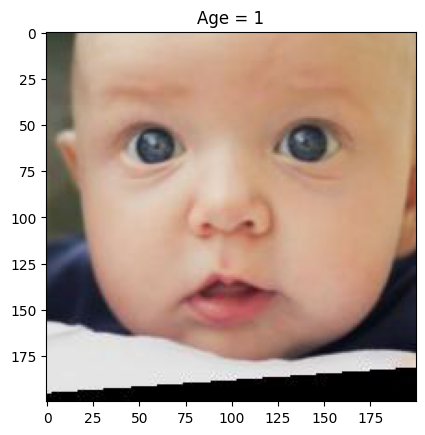

In [5]:
path = '/content/facial-age-data/face_age/face_age/'

#Ejemplo
img = mpimg.imread(path+'001/16.png')
plt.imshow(img)
plt.title('Age = 1')
plt.show()

### Función de Recorte con MTCNN
Definimos la función para procesar, recortar la cara detectada por MTCNN y redimensionar la imagen resultante a $224 \times 224$ píxeles.

In [6]:
from mtcnn import MTCNN
import numpy as np

# Create a detector instance
detector = MTCNN(device="CPU:0")

# Asegurar que la imagen esté en el formato uint8 (0-255) que MTCNN requiere
if img.dtype != np.uint8:
    if img.max() <= 1.0:
        img_uint8 = (img * 255).astype(np.uint8)
    else:
        img_uint8 = img.astype(np.uint8)
else:
    img_uint8 = img

# Detect faces in the image
result = detector.detect_faces(img_uint8)

# Display the result
print(result)

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


[{'box': [18, 0, 179, 186], 'confidence': np.float64(0.9980477094650269), 'keypoints': {'nose': [np.int64(95), np.int64(98)], 'mouth_right': [np.int64(125), np.int64(144)], 'right_eye': [np.int64(139), np.int64(61)], 'left_eye': [np.int64(59), np.int64(64)], 'mouth_left': [np.int64(73), np.int64(146)]}}]


In [7]:
import cv2
import numpy as np
from PIL import Image

def crop_face_mtcnn(image_path, target_size=(224, 224)):
    # Cargar la imagen usando OpenCV
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        return None

    # Convertir de BGR (OpenCV) a RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Inicializar con la imagen completa como fallback
    face_img = img_rgb

    try:
        # Detectar rostros de forma segura con MTCNN
        detections = detector.detect_faces(img_rgb)

        if len(detections) > 0:
            # Tomar la detección con mayor nivel de confianza o la más grande
            best_detection = max(detections, key=lambda item: item['box'][2] * item['box'][3])
            x, y, width, height = best_detection['box']

            # Asegurar que las coordenadas de la caja estén estrictamente dentro de los límites de la imagen
            x = max(0, int(x))
            y = max(0, int(y))
            x2 = min(img_rgb.shape[1], x + int(width))
            y2 = min(img_rgb.shape[0], y + int(height))

            # Solo recortar si las dimensiones obtenidas son coherentes y mayores a cero
            if (x2 > x) and (y2 > y):
                face_img = img_rgb[y:y2, x:x2]
    except Exception as e:
        # En caso de cualquier error interno en el detector MTCNN (ej. fallos en ONet), se usa la imagen completa
        pass

    # Convertir a objeto de imagen PIL y redimensionar
    try:
        face_pil = Image.fromarray(face_img)
        face_pil = face_pil.resize(target_size)
    except Exception as e:
        # Segundo respaldo en caso de errores de formato con PIL
        img_pil_fallback = Image.fromarray(img_rgb)
        face_pil = img_pil_fallback.resize(target_size)

    return face_pil

### Demostración del Recorte con MTCNN
Probemos visualmente cómo funciona nuestro nuevo recortador con una de las imágenes del dataset.

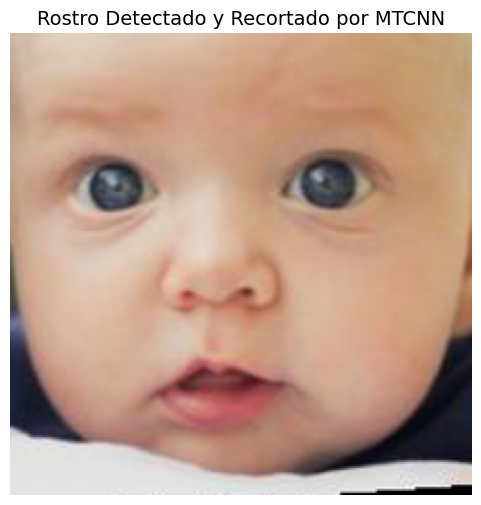

In [8]:
ejemplo_ruta = path + '001/16.png'
rostro_recortado = crop_face_mtcnn(ejemplo_ruta)

if rostro_recortado is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(rostro_recortado)
    plt.title("Rostro Detectado y Recortado por MTCNN", fontsize=14)
    plt.axis('off')
    plt.show()
else:
    print("No se pudo cargar o procesar la imagen de prueba.")

### Creación del Generador Personalizado
Implementamos un generador de secuencias de Keras que procesará las imágenes en tiempo de entrenamiento utilizando la función `crop_face_mtcnn` recién construida.

## Obteniendo los datos de entrenamiento, validación y testeo

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Creamos un DataFrame con las rutas de los archivos y sus respectivas edades (etiquetas)
file_paths = []
ages = []

for folder, _, files in os.walk(path):
    if folder != "face_age":
        for file in files:
            file_paths.append(os.path.join(folder, file))
            ages.append(str(folder[-3:]))  # Mantener como string o float según el generador

df_dataset = pd.DataFrame({
    'filepath': file_paths,
    'age': pd.to_numeric(ages)
})

# Split de los datos: 70% entrenamiento, 15% validación, 15% prueba
train_df, temp_df = train_test_split(df_dataset, test_size=0.3, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

# 2. Configurar el Generador de Datos (solo normalización)
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=True
)

val_generator = datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

Found 6844 validated image filenames.
Found 1467 validated image filenames.
Found 1467 validated image filenames.


In [10]:
import tensorflow as tf

class FaceCroppedGenerator(tf.keras.utils.Sequence):
    def __init__(self, dataframe, x_col, y_col, batch_size=32, target_size=(224, 224), shuffle=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.x_col = x_col
        self.y_col = y_col
        self.batch_size = batch_size
        self.target_size = target_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size : (index + 1) * self.batch_size]

        batch_images = []
        batch_labels = []

        for idx in batch_indices:
            row = self.dataframe.iloc[idx]
            img_path = row[self.x_col]
            label = row[self.y_col]

            # Aplicar la detección y recorte con MTCNN
            face_pil = crop_face_mtcnn(img_path, target_size=self.target_size)

            if face_pil is not None:
                img_arr = np.array(face_pil, dtype=np.float32) / 255.0  # Normalizar píxeles a [0.0, 1.0]
                batch_images.append(img_arr)
                batch_labels.append(label)

        return np.array(batch_images), np.array(batch_labels, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Creamos los nuevos generadores con el preprocesamiento de MTCNN integrado
train_generator_cropped = FaceCroppedGenerator(train_df, x_col='filepath', y_col='age', batch_size=32, shuffle=True)
val_generator_cropped = FaceCroppedGenerator(val_df, x_col='filepath', y_col='age', batch_size=32, shuffle=False)
test_generator_cropped = FaceCroppedGenerator(test_df, x_col='filepath', y_col='age', batch_size=32, shuffle=False)

print("Generadores basados en MTCNN listos para ser entrenados.")

Generadores basados en MTCNN listos para ser entrenados.


### Preprocesamiento Completo: Recortar y Guardar en Disco

Con este código vamos a crear una nueva carpeta llamada `cropped_dataset` donde guardaremos todas las imágenes recortadas por MTCNN estructuradas por edades. De esta manera, el modelo podrá cargarlas instantáneamente durante el entrenamiento sin retrasos de CPU.

In [14]:
import os
from tqdm.notebook import tqdm

# Definir el nuevo directorio de salida para las imágenes recortadas
cropped_base_path = '/content/cropped_dataset/'
os.makedirs(cropped_base_path, exist_ok=True)

# Listas para almacenar las rutas de las nuevas imágenes procesadas de forma exitosa
cropped_file_paths = []
cropped_ages = []

print("Iniciando el proceso de recorte de todo el dataset con MTCNN...")

# Recorrer el DataFrame original y procesar cada imagen
for idx, row in tqdm(df_dataset.iterrows(), total=len(df_dataset)):
    original_path = row['filepath']
    age = row['age']

    # Crear la subcarpeta correspondiente a la edad en el nuevo directorio
    age_folder = os.path.join(cropped_base_path, f"{age:03d}")
    os.makedirs(age_folder, exist_ok=True)

    # Definir la ruta de destino de la imagen recortada
    filename = os.path.basename(original_path)
    destination_path = os.path.join(age_folder, filename)

    # Aplicar el recorte seguro con MTCNN
    cropped_img_pil = crop_face_mtcnn(original_path, target_size=(224, 224))

    if cropped_img_pil is not None:
        # Guardar la imagen recortada en disco
        cropped_img_pil.save(destination_path)
        cropped_file_paths.append(destination_path)
        cropped_ages.append(age)

# Crear un nuevo DataFrame con las rutas de las imágenes optimizadas
df_cropped_dataset = pd.DataFrame({
    'filepath': cropped_file_paths,
    'age': cropped_ages
})

print(f"Proceso finalizado. Se han procesado y guardado {len(df_cropped_dataset)} imágenes con éxito.")
display(df_cropped_dataset.head())

Iniciando el proceso de recorte de todo el dataset con MTCNN...


  0%|          | 0/9778 [00:00<?, ?it/s]

Proceso finalizado. Se han procesado y guardado 9778 imágenes con éxito.


,filepath,age
0,/content/cropped_dataset/041/7853.png,41
1,/content/cropped_dataset/041/132.png,41
2,/content/cropped_dataset/041/910.png,41
3,/content/cropped_dataset/041/8743.png,41
4,/content/cropped_dataset/041/6598.png,41


### Generar Nuevos Sets de Datos y Cargadores Eficientes

Ahora dividiremos nuestro dataset pre-recortado en entrenamiento, validación y prueba, y utilizaremos cargadores de Keras optimizados nativamente que se ejecutarán a máxima velocidad.

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dividir el nuevo dataset pre-recortado (70% Train, 15% Val, 15% Test)
train_crop_df, temp_crop_df = train_test_split(df_cropped_dataset, test_size=0.3, random_state=42)
val_crop_df, test_crop_df = train_test_split(temp_crop_df, test_size=0.5, random_state=42)

# Configurar el generador que solo normaliza los píxeles (las imágenes ya están recortadas a 224x224)
fast_datagen = ImageDataGenerator(rescale=1./255)

fast_train_generator = fast_datagen.flow_from_dataframe(
    dataframe=train_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=True
)

fast_val_generator = fast_datagen.flow_from_dataframe(
    dataframe=val_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

fast_test_generator = fast_datagen.flow_from_dataframe(
    dataframe=test_crop_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

print("¡Nuevos generadores de alta velocidad listos!")

Found 6844 validated image filenames.
Found 1467 validated image filenames.
Found 1467 validated image filenames.
¡Nuevos generadores de alta velocidad listos!


### Ejemplo de uso para el entrenamiento
Para entrenar tu modelo ahora de forma ultra rápida, simplemente debes pasar estos nuevos generadores (`fast_train_generator` y `fast_val_generator`) a la función `.fit()`. Por ejemplo:

```python
history = model.fit(
    fast_train_generator,
    validation_data=fast_val_generator,
    epochs=50,
    callbacks=[checkpointer, lr_reducer, early_stopping]
)
```

Total de imágenes en el dataset: 9778
Edad mínima: 1 años
Edad máxima: 110 años
Edad promedio: 29.41 años
Mediana de edad: 25.0 años


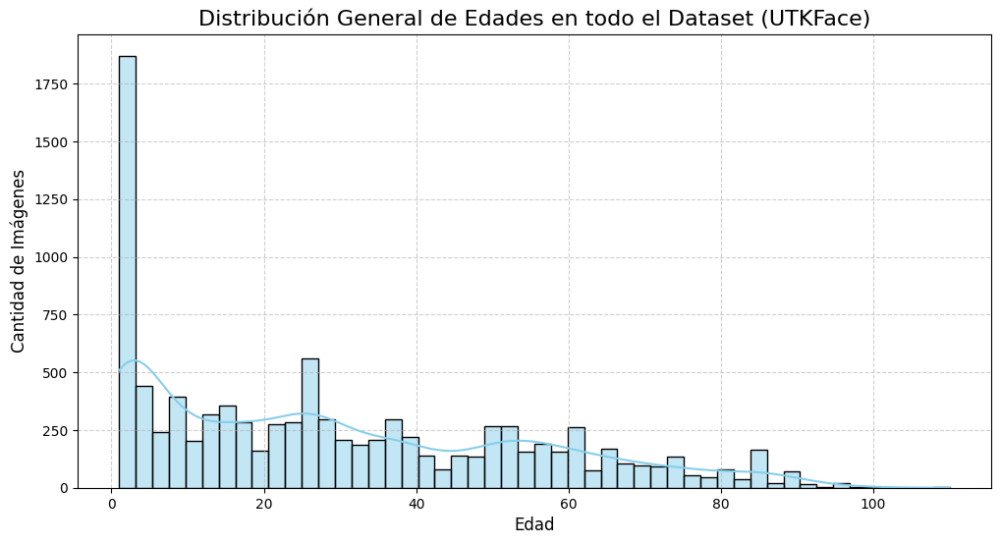

In [11]:

# Configurar el tamaño de la gráfica
plt.figure(figsize=(12, 6))

# Graficar la distribución de edades en todo el dataset
sns.histplot(df_dataset['age'], bins=50, kde=True, color='skyblue')

plt.title('Distribución General de Edades en todo el Dataset (UTKFace)', fontsize=16)
plt.xlabel('Edad', fontsize=12)
plt.ylabel('Cantidad de Imágenes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar estadísticas básicas
print(f"Total de imágenes en el dataset: {len(df_dataset)}")
print(f"Edad mínima: {df_dataset['age'].min()} años")
print(f"Edad máxima: {df_dataset['age'].max()} años")
print(f"Edad promedio: {df_dataset['age'].mean():.2f} años")
print(f"Mediana de edad: {df_dataset['age'].median()} años")

plt.show()

### Creación del modelo



In [12]:
import keras
from keras.layers import Add, Activation, BatchNormalization

def residual_block(input_tensor, filters, kernel_size=3):
    x = Conv2D(filters, kernel_size, padding='same')(input_tensor)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)

    shortcut = Conv2D(filters, (1, 1), padding='same')(input_tensor)
    shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x

def build_resnet_age_model(input_shape=(224, 224, 3)):
    inputs = Input(shape=input_shape)


    x = Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 64)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 128)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 256)
    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs, outputs)
    return model

model = build_resnet_age_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    147,584 │ activation_2[0][

 Total params: 1,244,865 (4.75 MB)

 Trainable params: 1,242,177 (4.74 MB)

 Non-trainable params: 2,688 (10.50 KB)

In [ ]:
base_modelrest50 = keras.applications.ResNet50(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)
base_modelrest50.trainable = False


modelrest50 = tf.keras.Sequential([
    base_modelrest50,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(1, activation='linear')
])

base_modelrest152 = keras.applications.ResNet152(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)
base_modelrest152.trainable = False

modelrest152 = tf.keras.Sequential([
    base_modelrest152,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(1, activation='linear')
])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


## Compilación y Entrenamiento del Modelo

In [ ]:
checkpointer = ModelCheckpoint(
    'resnet50.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

modelrest50.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mean_squared_error', metrics=['mean_absolute_error'])

history = modelrest50.fit(
    train_generator_cropped,
    validation_data=val_generator_cropped,
    epochs=50,
    callbacks=[checkpointer, lr_reducer, early_stopping]
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 812ms/step - loss: 777.2396 - mean_absolute_error: 22.3152
Epoch 1: val_loss improved from None to 626.84351, saving model to resnet50.keras

Epoch 1: finished saving model to resnet50.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 233s 1s/step - loss: 666.1847 - mean_absolute_error: 21.2778 - val_loss: 626.8435 - val_mean_absolute_error: 20.8802 - learning_rate: 0.0010
Epoch 2/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 804ms/step - loss: 614.0279 - mean_absolute_error: 20.6992
Epoch 2: val_loss improved from 626.84351 to 624.86462, saving model to resnet50.keras

Epoch 2: finished saving model to resnet50.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 211s 985ms/step - loss: 623.1376 - mean_absolute_error: 20.8446 - val_loss: 624.8646 - val_mean_absolute_error: 20.8410 - learning_rate: 0.0010
Epoch 3/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 810ms/step - loss: 631.6004 - mean_absolute_error: 21.0721
Epoch 3: val_loss improved from 624.86462 to 621.28210, saving model to resnet50.k

In [16]:
checkpointer = ModelCheckpoint(
    'resnet50.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])

history = model.fit(
    fast_train_generator,
    validation_data=fast_val_generator,
    epochs=50,
    callbacks=[checkpointer, lr_reducer, early_stopping]
)

Epoch 1/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - loss: 471.6909 - mean_absolute_error: 17.4480
Epoch 1: val_loss improved from None to 1431.93591, saving model to resnet50.keras

Epoch 1: finished saving model to resnet50.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 106s 381ms/step - loss: 409.3868 - mean_absolute_error: 16.0770 - val_loss: 1431.9359 - val_mean_absolute_error: 28.7974 - learning_rate: 0.0010
Epoch 2/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - loss: 329.0633 - mean_absolute_error: 14.1293
Epoch 2: val_loss improved from 1431.93591 to 342.90756, saving model to resnet50.keras

Epoch 2: finished saving model to resnet50.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 37s 171ms/step - loss: 308.1863 - mean_absolute_error: 13.5673 - val_loss: 342.9076 - val_mean_absolute_error: 14.8644 - learning_rate: 0.0010
Epoch 3/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - loss: 271.4015 - mean_absolute_error: 12.4570
Epoch 3: val_loss improved from 342.90756 to 269.99847, saving model to resne

### Visualización del Historial de Entrenamiento

Graficaremos la evolución de la pérdida (MSE) y del error absoluto medio (MAE) para analizar el comportamiento y la convergencia del modelo.

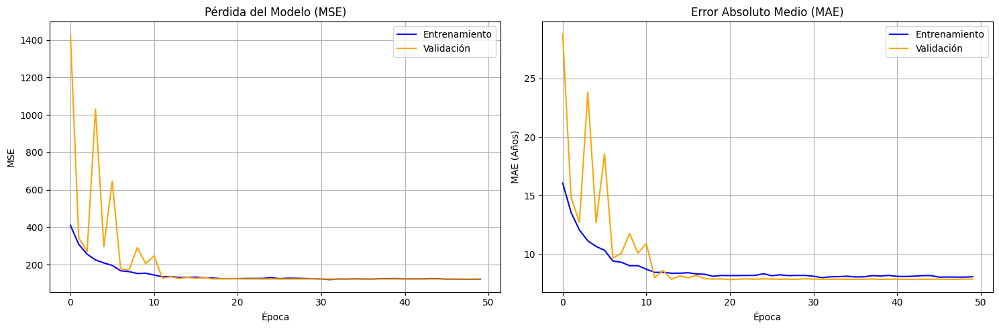

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de Pérdida (MSE)
ax1.plot(history.history['loss'], label='Entrenamiento', color='blue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Pérdida del Modelo (MSE)')
ax1.set_xlabel('Época')
ax1.set_ylabel('MSE')
ax1.legend()
ax1.grid(True)

# Gráfico de MAE (Error Medio Absoluto)
ax2.plot(history.history['mean_absolute_error'], label='Entrenamiento', color='blue')
ax2.plot(history.history['val_mean_absolute_error'], label='Validación', color='orange')
ax2.set_title('Error Absoluto Medio (MAE)')
ax2.set_xlabel('Época')
ax2.set_ylabel('MAE (Años)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Evaluación con el Conjunto de Prueba
Evaluamos el modelo final con datos totalmente nuevos para calcular el error definitivo de predicción.

In [24]:
# Evaluamos el modelo final con el test_generator
test_loss, test_mae = model.evaluate(fast_test_generator)
print(f"Pérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - loss: 121.5677 - mean_absolute_error: 7.8694
Pérdida (MSE) en Test: 121.5677
Error Absoluto Medio (MAE) en Test: 7.9 años


### Visualización de Predicciones de Ejemplo

Tomaremos un pequeño grupo de imágenes del conjunto de prueba para comparar visualmente la edad real de la persona frente a la edad estimada por nuestro modelo residual.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step


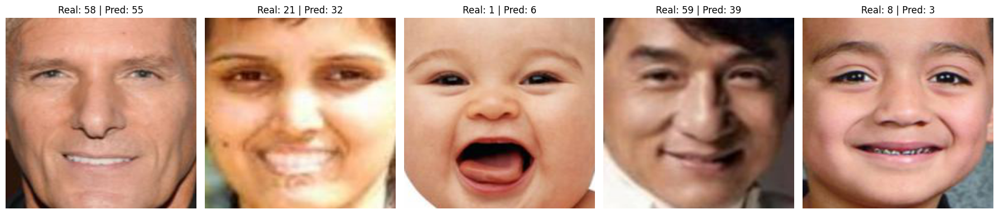

In [37]:
# Obtener un lote de imágenes y etiquetas del generador de pruebas
x_test_batch, y_test_batch = next(fast_test_generator)

# Realizar las predicciones con el modelo
predictions = model.predict(x_test_batch)

# Configurar la visualización de 5 ejemplos redondeando las predicciones
plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test_batch[i])
    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(predictions[i][0])))

    plt.title(f"Real: {real_age} | Pred: {predicted_age}")
    plt.axis('off')

plt.tight_layout()
plt.show()

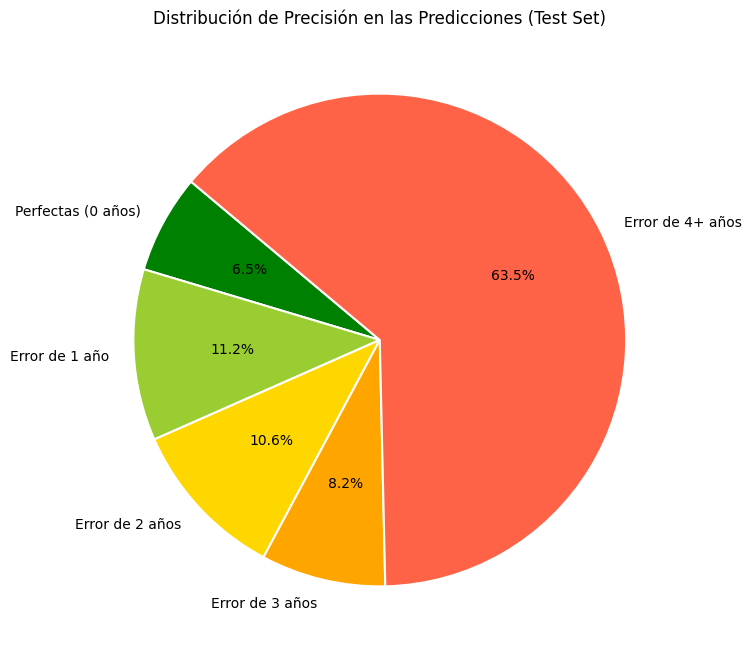

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas
fast_test_generator.reset()
all_preds = []
all_real = []

# Iterar sobre todo el generador para asegurar que cubrimos todos los datos de test
for _ in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)
    preds = model.predict(x_batch, verbose=0)
    all_preds.extend(preds.flatten())
    all_real.extend(y_batch)

all_preds = np.array(all_preds)
all_real = np.array(all_real)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds = np.round(all_preds)
diferencias = np.abs(all_real - rounded_preds)

# 3. Clasificar los errores en categorías detalladas
perfectas = np.sum(diferencias == 0)
error_1_ano = np.sum(diferencias == 1)
error_2_anos = np.sum(diferencias == 2)
error_3_anos = np.sum(diferencias == 3)
resto = np.sum(diferencias >= 4)

total = len(diferencias)

# 4. Configurar datos del gráfico de pastel
etiquetas = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades = [perfectas, error_1_ano, error_2_anos, error_3_anos, resto]
colores = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones (Test Set)')
plt.show()

### Visualización de Atención del Modelo con Grad-CAM

Dado que el modelo es una red convolucional residual (ResNet), podemos usar **Grad-CAM** para obtener un mapa de calor sobre las zonas del rostro que más influyeron en la predicción de la edad.

Usando la última capa convolucional encontrada: conv2d_9


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


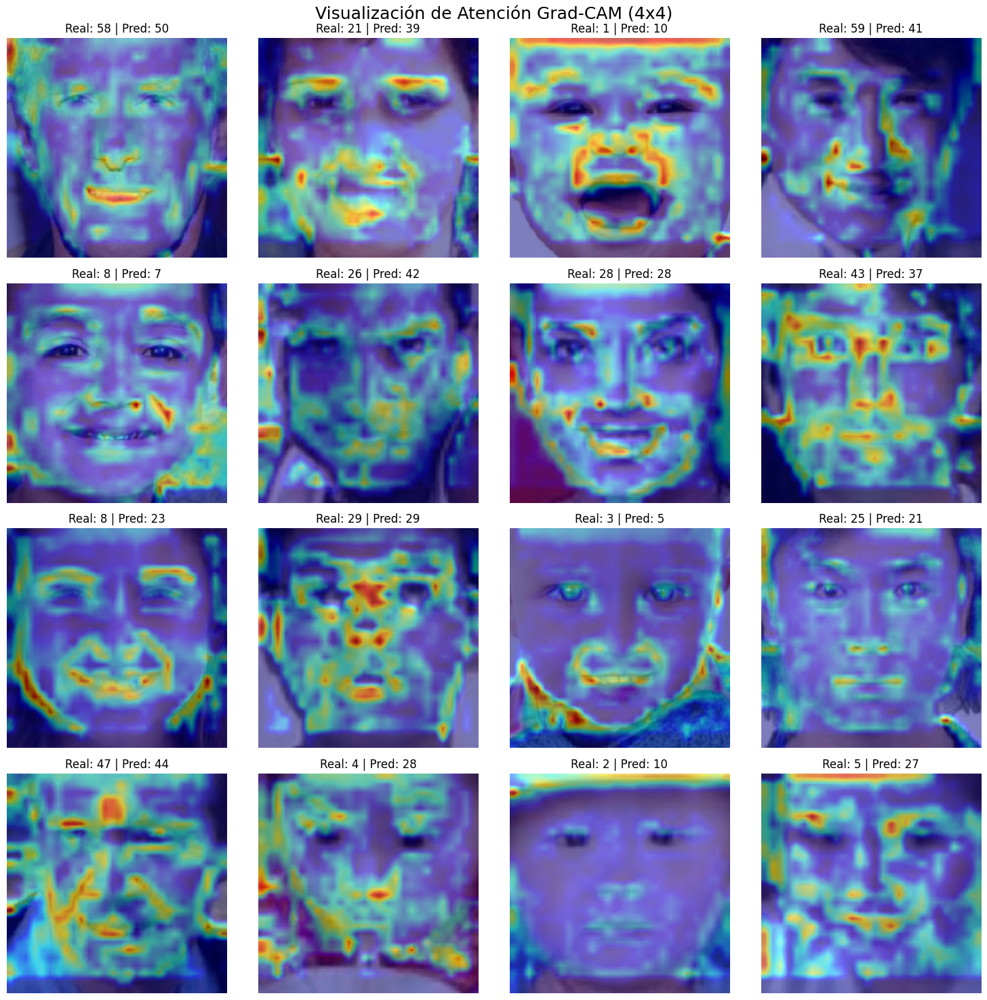

In [30]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Crear un modelo que mapee la imagen de entrada a las activaciones de la última capa convolucional
    # y a la salida de predicción del modelo
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcular el gradiente de la predicción respecto a los mapas de características de la última capa conv
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            score = preds[:, 0]
        else:
            score = preds[:, pred_index]

    # Gradiente del valor de salida respecto al mapa de características
    grads = tape.gradient(score, last_conv_layer_output)

    # Reducir los gradientes a un vector de pesos por canal
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal en el mapa de características por su "importancia"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizar el mapa de calor entre 0 y 1 para su visualización
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def superimpose_heatmap(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    # Reescalar el mapa de calor al tamaño de la imagen original
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, colormap)

    # Convertir de BGR (OpenCV) a RGB
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Superponer el mapa de calor sobre la imagen original
    superimposed_img = heatmap * alpha + img * (1 - alpha)
    # Normalizar para mostrar correctamente con plt.imshow
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    return superimposed_img

# Encontrar el nombre de la última capa convolucional de la arquitectura
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"Usando la última capa convolucional encontrada: {last_conv_layer_name}")

# Resetear e iterar el generador de pruebas para obtener suficientes imágenes
fast_test_generator.reset()
x_test_batch, y_test_batch = next(test_generator)

# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes con la atención Grad-CAM
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar mapa de calor
    heatmap = make_gradcam_heatmap(img_input, model, last_conv_layer_name)

    # Convertir imagen normalizada (0-1) a rango 0-255 para OpenCV
    img_255 = np.uint8(img * 255)
    gradcam_img = superimpose_heatmap(img_255, heatmap, alpha=0.5)

    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(model.predict(img_input, verbose=0)[0][0])))

    # Dibujar en una cuadrícula de 4x4 sólo la visualización Grad-CAM
    plt.subplot(4, 4, i + 1)
    plt.imshow(gradcam_img)
    plt.title(f"Real: {real_age} | Pred: {predicted_age}", fontsize=12)
    plt.axis('off')

plt.suptitle("Visualización de Atención Grad-CAM (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

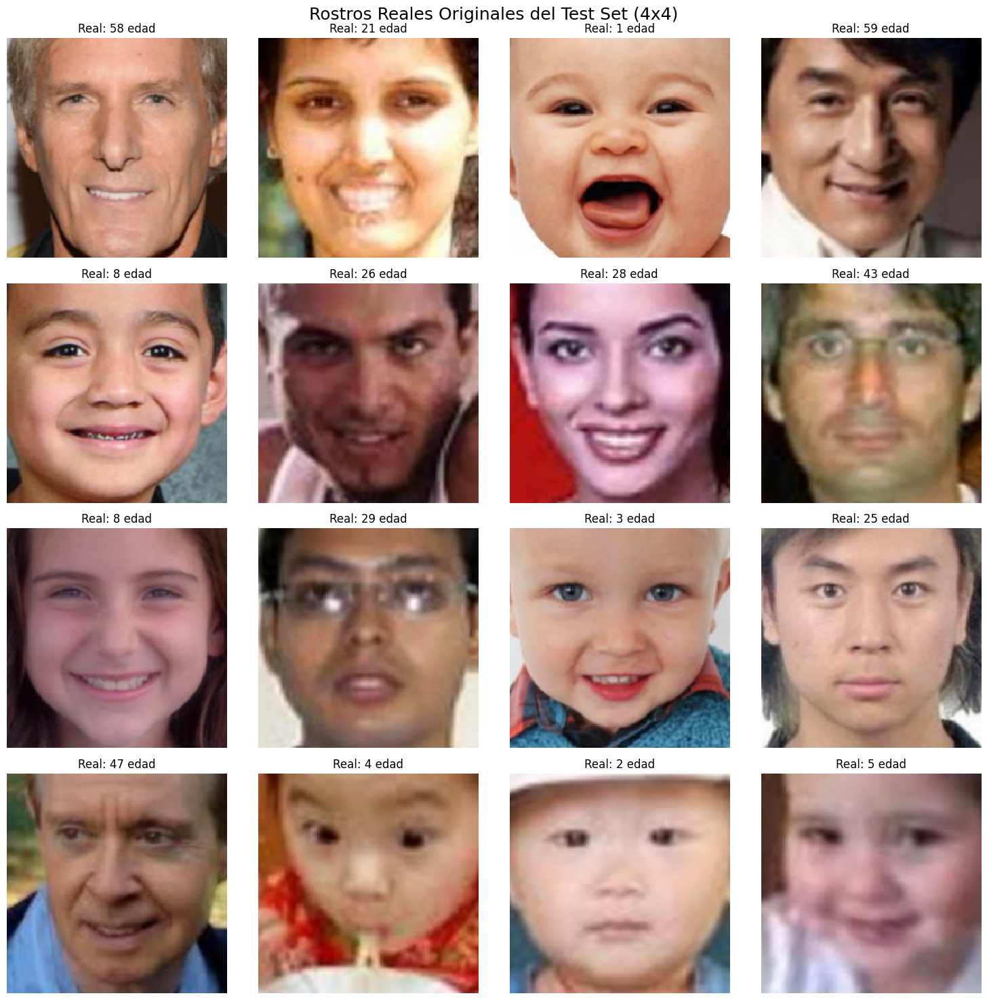

In [31]:
# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes reales originales
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    real_age = int(y_test_batch[i])

    # Dibujar la cara real original sin mapas de calor
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Real: {real_age} edad", fontsize=12)
    plt.axis('off')

plt.suptitle("Rostros Reales Originales del Test Set (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

## Celdas extra (No las eliminé por si acaso pero no se usan)

In [ ]:
X=[]
Y=[]
for folder,_,files in os.walk(path):
    if folder!="face_age":
        for file in files:
            # Cargando Imagenes
            image = Image.open(folder +"/"+ file)
            image = image.convert('RGB')
            image = image.resize((224, 224))
            X.append(np.array(image))
            # Obteniendo la edad real
            Y.append(int(folder[-3:]))

X = np.array(X)
Y = np.array(Y)
# Normalizacion
X = X.astype('float32')
X /= 255.0
print(X[0],Y[0])

[[[0.6509804  0.54509807 0.47843137]
  [0.6313726  0.5254902  0.45882353]
  [0.5882353  0.48235294 0.41568628]
  ...
  [0.61960787 0.5058824  0.4509804 ]
  [0.5294118  0.40392157 0.3529412 ]
  [0.5254902  0.39215687 0.3529412 ]]

 [[0.69411767 0.5882353  0.52156866]
  [0.65882355 0.5529412  0.4862745 ]
  [0.6        0.49411765 0.42745098]
  ...
  [0.59607846 0.48235294 0.42745098]
  [0.5058824  0.38039216 0.3372549 ]
  [0.49803922 0.3647059  0.3254902 ]]

 [[0.6627451  0.5568628  0.49019608]
  [0.6901961  0.58431375 0.5176471 ]
  [0.68235296 0.5764706  0.50980395]
  ...
  [0.5372549  0.42745098 0.37254903]
  [0.44313726 0.31764707 0.27450982]
  [0.43137255 0.30588236 0.2627451 ]]

 ...

 [[0.627451   0.4627451  0.4       ]
  [0.56078434 0.40784314 0.34117648]
  [0.53333336 0.38039216 0.3137255 ]
  ...
  [0.8509804  0.84705883 0.827451  ]
  [0.8392157  0.8352941  0.8156863 ]
  [0.83137256 0.827451   0.8117647 ]]

 [[0.6313726  0.46666667 0.40392157]
  [0.56078434 0.40784314 0.34117648]


In [ ]:

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42,shuffle=True)
print(len(X_train),len(Y_test))

7822 1956


Age =  75


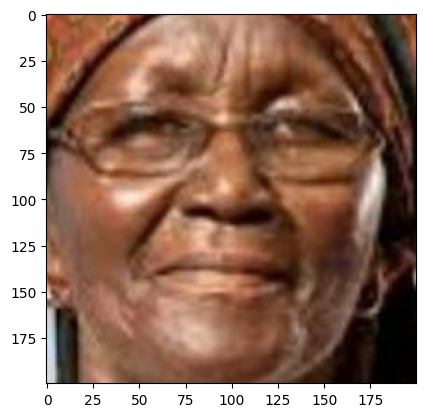

In [ ]:
plt.imshow(X_train[300])
print('Age = ',Y_train[300])

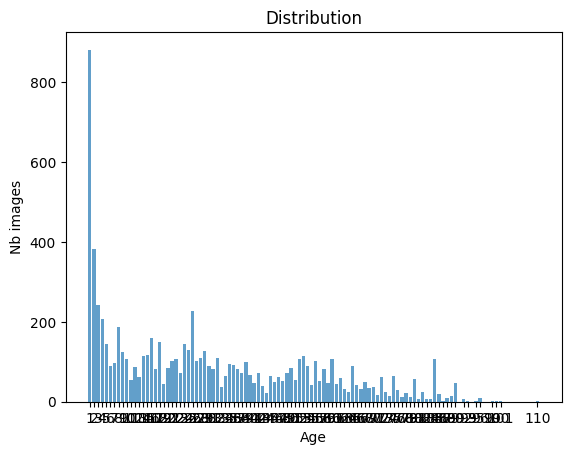

In [ ]:
unique, counts = np.unique(Y_train, return_counts=True)
plt.bar(unique, counts, align='center', alpha=0.7)
plt.xticks(unique, [str(i) for i in unique])
plt.xlabel('Age')
plt.ylabel('Nb images')
plt.title('Distribution')
plt.show()

### Prueba2

In [43]:
import tensorflow as tf

# 1. Cargar el modelo guardado de forma correcta usando Keras de TensorFlow
model_path = '/content/modelface (2).keras'
try:
    model2 = tf.keras.models.load_model(model_path)
    print("¡Modelo 'modelface (2).keras' cargado correctamente!")
    model2.summary()
except Exception as e:
    print(f"Error al cargar el modelo: {e}")

¡Modelo 'modelface (2).keras' cargado correctamente!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    147,584 │ activation_2[0][

 Total params: 3,729,221 (14.23 MB)

 Trainable params: 1,242,177 (4.74 MB)

 Non-trainable params: 2,688 (10.50 KB)

 Optimizer params: 2,484,356 (9.48 MB)

In [44]:
# 2. Aplicar Transfer Learning / Fine-Tuning
# Congelamos las capas base convolucionales y dejamos solo entrenables las capas densas superiores
# Si tu modelo tiene una estructura secuencial o funcional clásica, congelamos casi todas las capas excepto las últimas

# Congelar las capas iniciales (por ejemplo, el 80% del modelo)
layers_to_freeze = int(len(model2.layers) * 0.8)
for layer in model2.layers[:layers_to_freeze]:
    layer.trainable = False
for layer in model2.layers[layers_to_freeze:]:
    layer.trainable = True

# Compilar de nuevo el modelo con una tasa de aprendizaje más baja para ajuste fino seguro
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

print("Configuración de Transfer Learning completada. Capas congeladas de manera exitosa.")

Configuración de Transfer Learning completada. Capas congeladas de manera exitosa.


In [45]:
# 3. Configurar callbacks y entrenar con los generadores de alta velocidad
checkpointer_transfer = ModelCheckpoint(
    'modelface_transfer_learning.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

history_transfer = model2.fit(
    fast_train_generator,
    validation_data=fast_val_generator,
    epochs=15,  # Usamos menos épocas para transfer learning / fine-tuning rápido
    callbacks=[checkpointer_transfer, lr_reducer, early_stopping]
)

Epoch 1/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 85.6587 - mean_absolute_error: 6.3834
Epoch 1: val_loss improved from None to 64.67081, saving model to modelface_transfer_learning.keras

Epoch 1: finished saving model to modelface_transfer_learning.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 41s 172ms/step - loss: 84.8555 - mean_absolute_error: 6.4053 - val_loss: 64.6708 - val_mean_absolute_error: 5.4027 - learning_rate: 1.0000e-04
Epoch 2/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - loss: 84.6999 - mean_absolute_error: 6.4620
Epoch 2: val_loss improved from 64.67081 to 64.31795, saving model to modelface_transfer_learning.keras

Epoch 2: finished saving model to modelface_transfer_learning.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 29s 136ms/step - loss: 81.5869 - mean_absolute_error: 6.3419 - val_loss: 64.3179 - val_mean_absolute_error: 5.3888 - learning_rate: 1.0000e-04
Epoch 3/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 81.3971 - mean_absolute_error: 6.3276
Epoch 3: val_l

In [46]:
# Evaluamos el modelo final con el test_generator
test_loss, test_mae = model2.evaluate(fast_test_generator)
print(f"Pérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - loss: 57.9024 - mean_absolute_error: 5.3302
Pérdida (MSE) en Test: 57.9024
Error Absoluto Medio (MAE) en Test: 5.3 años


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 993ms/step


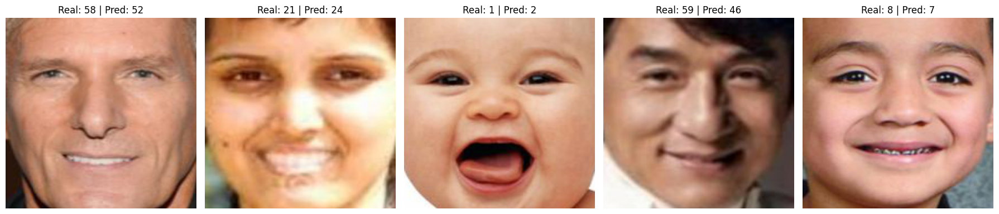

In [47]:
# Obtener un lote de imágenes y etiquetas del generador de pruebas
x_test_batch, y_test_batch = next(fast_test_generator)

# Realizar las predicciones con el modelo
predictions = model2.predict(x_test_batch)

# Configurar la visualización de 5 ejemplos redondeando las predicciones
plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test_batch[i])
    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(predictions[i][0])))

    plt.title(f"Real: {real_age} | Pred: {predicted_age}")
    plt.axis('off')

plt.tight_layout()
plt.show()

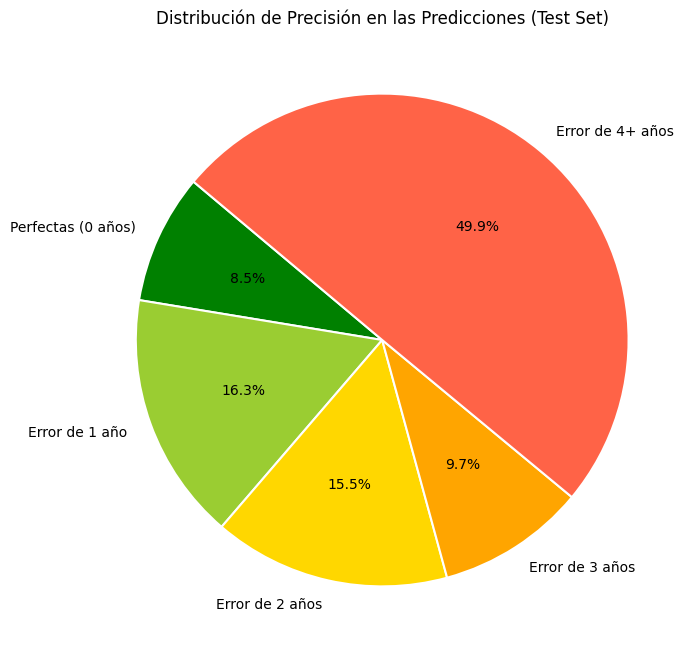

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas
fast_test_generator.reset()
all_preds = []
all_real = []

# Iterar sobre todo el generador para asegurar que cubrimos todos los datos de test
for _ in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)
    preds = model2.predict(x_batch, verbose=0)
    all_preds.extend(preds.flatten())
    all_real.extend(y_batch)

all_preds = np.array(all_preds)
all_real = np.array(all_real)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds = np.round(all_preds)
diferencias = np.abs(all_real - rounded_preds)

# 3. Clasificar los errores en categorías detalladas
perfectas = np.sum(diferencias == 0)
error_1_ano = np.sum(diferencias == 1)
error_2_anos = np.sum(diferencias == 2)
error_3_anos = np.sum(diferencias == 3)
resto = np.sum(diferencias >= 4)

total = len(diferencias)

# 4. Configurar datos del gráfico de pastel
etiquetas = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades = [perfectas, error_1_ano, error_2_anos, error_3_anos, resto]
colores = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones (Test Set)')
plt.show()

### Visualización de Atención del Modelo con Grad-CAM

Dado que el modelo es una red convolucional residual (ResNet), podemos usar **Grad-CAM** para obtener un mapa de calor sobre las zonas del rostro que más influyeron en la predicción de la edad.

Usando la última capa convolucional encontrada: conv2d_9


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


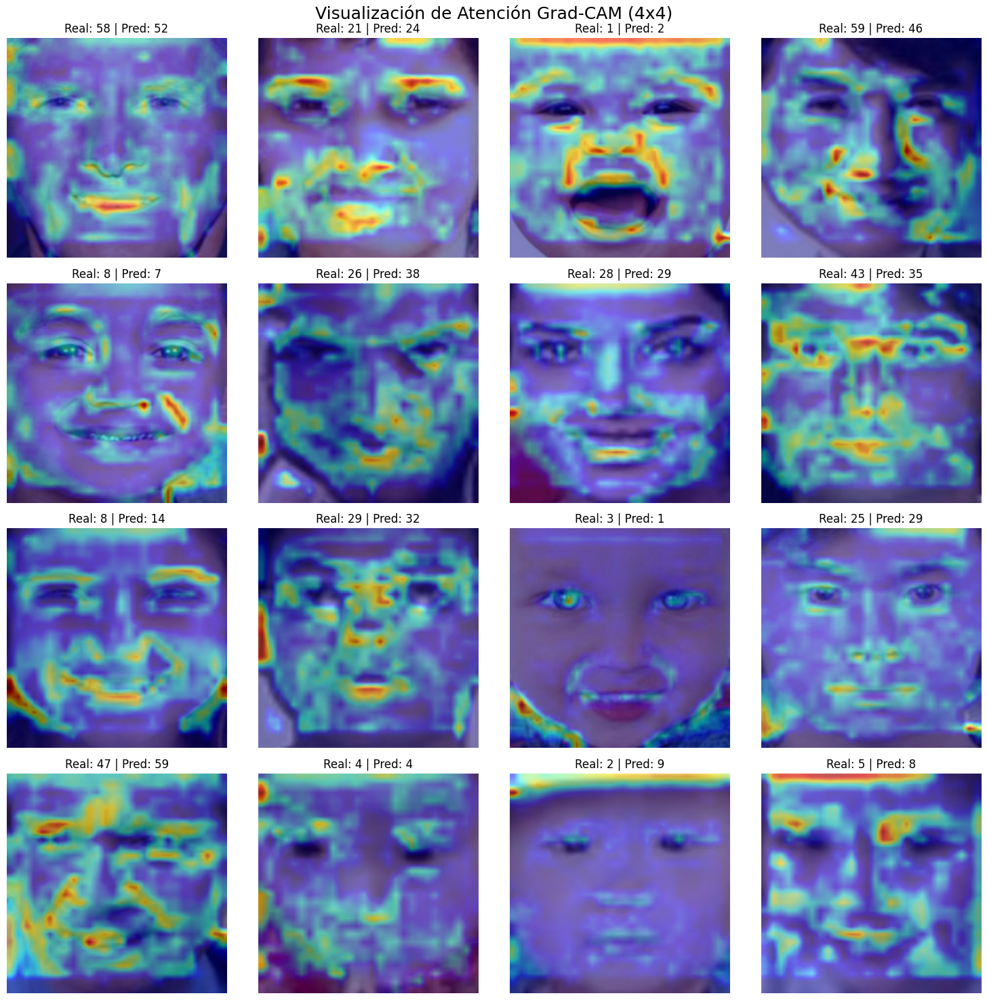

In [51]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Crear un modelo que mapee la imagen de entrada a las activaciones de la última capa convolucional
    # y a la salida de predicción del modelo
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcular el gradiente de la predicción respecto a los mapas de características de la última capa conv
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            score = preds[:, 0]
        else:
            score = preds[:, pred_index]

    # Gradiente del valor de salida respecto al mapa de características
    grads = tape.gradient(score, last_conv_layer_output)

    # Reducir los gradientes a un vector de pesos por canal
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal en el mapa de características por su "importancia"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizar el mapa de calor entre 0 y 1 para su visualización
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def superimpose_heatmap(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    # Reescalar el mapa de calor al tamaño de la imagen original
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, colormap)

    # Convertir de BGR (OpenCV) a RGB
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Superponer el mapa de calor sobre la imagen original
    superimposed_img = heatmap * alpha + img * (1 - alpha)
    # Normalizar para mostrar correctamente con plt.imshow
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    return superimposed_img

# Encontrar el nombre de la última capa convolucional de la arquitectura
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"Usando la última capa convolucional encontrada: {last_conv_layer_name}")

# Resetear e iterar el generador de pruebas para obtener suficientes imágenes
fast_test_generator.reset()
x_test_batch, y_test_batch = next(fast_test_generator)

# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes con la atención Grad-CAM
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar mapa de calor
    heatmap = make_gradcam_heatmap(img_input, model, last_conv_layer_name)

    # Convertir imagen normalizada (0-1) a rango 0-255 para OpenCV
    img_255 = np.uint8(img * 255)
    gradcam_img = superimpose_heatmap(img_255, heatmap, alpha=0.5)

    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(model2.predict(img_input, verbose=0)[0][0])))

    # Dibujar en una cuadrícula de 4x4 sólo la visualización Grad-CAM
    plt.subplot(4, 4, i + 1)
    plt.imshow(gradcam_img)
    plt.title(f"Real: {real_age} | Pred: {predicted_age}", fontsize=12)
    plt.axis('off')

plt.suptitle("Visualización de Atención Grad-CAM (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

### Prueba3

Para esta prueba, utilizaremos la librería **DeepFace**, la cual ya cuenta con modelos de redes neuronales convolucionales preentrenados y optimizados específicamente para la predicción de edad en rostros humanos. Esto nos permite evadir las limitaciones de los pesos estándar de ImageNet (que están orientados a objetos) y verificar la precisión directamente sobre nuestro conjunto de prueba optimizado `fast_test_generator`.

In [52]:
pip install deepface

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 68.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 11.2 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [deepface]


In [53]:
import numpy as np
from deepface import DeepFace
import matplotlib.pyplot as plt

# Obtener un lote completo de imágenes y sus edades reales desde el generador de pruebas
fast_test_generator.reset()

all_real_ages = []
all_pred_ages = []

# Evaluaremos las primeras 100 imágenes del test_generator para realizar una prueba rápida y precisa
max_samples = 100
samples_evaluated = 0

print("Iniciando evaluación con el modelo preentrenado de DeepFace...")

for i in range(len(fast_test_generator)):
    if samples_evaluated >= max_samples:
        break
    x_batch, y_batch = next(fast_test_generator)

    for j in range(len(x_batch)):
        if samples_evaluated >= max_samples:
            break

        # La imagen está en rango [0, 1] y tamaño (224, 224, 3).
        # La convertimos a formato de píxeles [0, 255] que espera DeepFace
        img_255 = np.uint8(x_batch[j] * 255)

        try:
            # Usamos el detector de atributos faciales integrado de DeepFace sin forzar detección extra
            objs = DeepFace.analyze(img_path=img_255, actions=['age'], enforce_detection=False, silent=True)
            pred_age = objs[0]['age']
        except Exception as e:
            pred_age = np.mean(all_real_ages) if len(all_real_ages) > 0 else 29 # Fallback

        all_real_ages.append(y_batch[j])
        all_pred_ages.append(pred_age)
        samples_evaluated += 1

all_real_ages = np.array(all_real_ages)
all_pred_ages = np.array(all_pred_ages)

# Calcular métricas
mae = np.mean(np.abs(all_real_ages - all_pred_ages))
mse = np.mean((all_real_ages - all_pred_ages) ** 2)

print(f"\n--- Resultados del Modelo Preentrenado ---")
print(f"Muestras evaluadas: {samples_evaluated}")
print(f"Error Absoluto Medio (MAE): {mae:.2f} años")
print(f"Error Cuadrático Medio (MSE): {mse:.2f}")

26-11-17 02:28:26 - Directory /root/.deepface has been created
26-11-17 02:28:26 - Directory /root/.deepface/weights has been created
Iniciando evaluación con el modelo preentrenado de DeepFace...
26-11-17 02:28:28 - 🔗 age_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5 to /root/.deepface/weights/age_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5
To: /root/.deepface/weights/age_model_weights.h5
100%|██████████| 539M/539M [00:48<00:00, 11.0MB/s]



--- Resultados del Modelo Preentrenado ---
Muestras evaluadas: 100
Error Absoluto Medio (MAE): 15.89 años
Error Cuadrático Medio (MSE): 362.79


In [55]:
from deepface import DeepFace
# Cargar el modelo base VGG-Face de manera correcta usando la API de DeepFace
model3 = DeepFace.build_model("VGG-Face")
print("¡Modelo VGG-Face cargado exitosamente en model3!")

26-11-17 02:34:22 - 🔗 vgg_face_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5 to /root/.deepface/weights/vgg_face_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5
To: /root/.deepface/weights/vgg_face_weights.h5
100%|██████████| 580M/580M [00:30<00:00, 18.9MB/s]


¡Modelo VGG-Face cargado exitosamente en model3!


### Fine-Tuning de VGG-Face (model3) para Regresión de Edad

Adaptamos la arquitectura base de VGG-Face congelando sus capas convolucionales inferiores y agregando una cabeza densa de regresión optimizada para estimar la edad en base a los embeddings del rostro.

In [58]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from tensorflow.keras.callbacks import ModelCheckpoint

# 1. Obtener la arquitectura Keras interna de VGG-Face
base_vgg = model3.model

# Congelar las capas iniciales (80% del modelo base)
num_layers_to_freeze = int(len(base_vgg.layers) * 0.8)
for layer in base_vgg.layers[:num_layers_to_freeze]:
    layer.trainable = False
for layer in base_vgg.layers[num_layers_to_freeze:]:
    layer.trainable = True

# 2. Agregar una cabeza de regresión secuencial utilizando la salida del modelo base
# Usamos la penúltima o última capa de representación
x = base_vgg.output
if len(x.shape) > 2:
    x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
output_layer = Dense(1, activation='linear')(x)

# Crear el modelo final adaptado para regresión de edad
model3_fine_tuned = Model(inputs=base_vgg.input, outputs=output_layer)

# 3. Compilar el modelo con una tasa de aprendizaje baja para fine-tuning seguro
model3_fine_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

print("¡Modelo VGG-Face adaptado y compilado con éxito para regresión!")

¡Modelo VGG-Face adaptado y compilado con éxito para regresión!


In [59]:
# 4. Entrenar por 15 épocas usando los generadores optimizados
checkpointer_vgg = ModelCheckpoint(
    'vgg_face_finetuned.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

history_vgg = model3_fine_tuned.fit(
    fast_train_generator,
    validation_data=fast_val_generator,
    epochs=15,
    callbacks=[checkpointer_vgg, lr_reducer, early_stopping]
)

Epoch 1/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - loss: 479.7103 - mean_absolute_error: 15.2824
Epoch 1: val_loss improved from None to 83.83856, saving model to vgg_face_finetuned.keras

Epoch 1: finished saving model to vgg_face_finetuned.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 144s 587ms/step - loss: 248.1563 - mean_absolute_error: 10.6517 - val_loss: 83.8386 - val_mean_absolute_error: 6.0666 - learning_rate: 1.0000e-04
Epoch 2/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - loss: 98.7613 - mean_absolute_error: 6.8057
Epoch 2: val_loss improved from 83.83856 to 76.21263, saving model to vgg_face_finetuned.keras

Epoch 2: finished saving model to vgg_face_finetuned.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 90s 419ms/step - loss: 98.7105 - mean_absolute_error: 6.7680 - val_loss: 76.2126 - val_mean_absolute_error: 5.8857 - learning_rate: 1.0000e-04
Epoch 3/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - loss: 86.7218 - mean_absolute_error: 6.3178
Epoch 3: val_loss did not improve from 76.212

### Actualizar Variable de Evaluación

Asignamos el modelo ajustado de vuelta a `model3.model` para mantener la compatibilidad con el bloque de evaluación posterior sin modificar su lógica estructurada.

In [60]:
# Reemplazamos el modelo interno del cliente para que la celda de testeo posterior use el modelo entrenado
model3.model = model3_fine_tuned
print("model3 actualizado con los pesos del Fine-Tuning.")

model3 actualizado con los pesos del Fine-Tuning.


In [61]:
import numpy as np

all_real_ages = []
all_pred_ages = []

# Reiniciar el generador para asegurar consistencia
fast_test_generator.reset()

print("Evaluando el modelo VGG-Face ajustado con el test_generator...")
for i in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)

    # Predecir con el modelo optimizado
    preds = model3.model.predict(x_batch, verbose=0)
    pred_flat = preds.flatten()

    all_pred_ages.extend(pred_flat)
    all_real_ages.extend(y_batch)

all_real_ages = np.array(all_real_ages)
all_pred_ages = np.array(all_pred_ages)

# Calcular métricas definitivas de prueba
test_loss = np.mean((all_real_ages - all_pred_ages) ** 2) # MSE
test_mae = np.mean(np.abs(all_real_ages - all_pred_ages))  # MAE

print(f"\nPérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

Evaluando el modelo VGG-Face ajustado con el test_generator...

Pérdida (MSE) en Test: 57.1119
Error Absoluto Medio (MAE) en Test: 5.0 años


### Distribución de Precisión de Predicciones para model3 (VGG-Face)

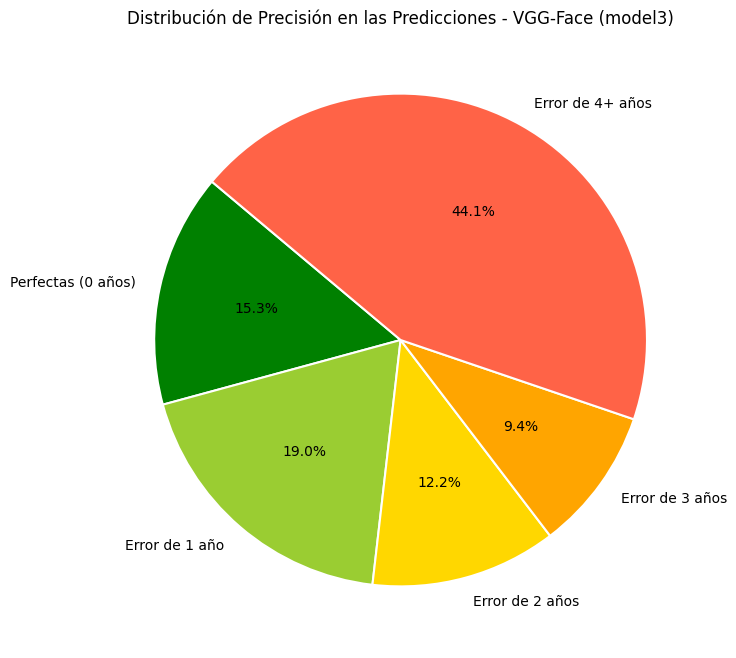

In [62]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas para model3
fast_test_generator.reset()
all_preds_vgg = []
all_real_vgg = []

for _ in range(len(fast_test_generator)):
    x_batch, y_batch = next(fast_test_generator)
    # Usamos model3.model para predecir
    preds = model3.model.predict(x_batch, verbose=0)
    all_preds_vgg.extend(preds.flatten())
    all_real_vgg.extend(y_batch)

all_preds_vgg = np.array(all_preds_vgg)
all_real_vgg = np.array(all_real_vgg)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds_vgg = np.round(all_preds_vgg)
diferencias_vgg = np.abs(all_real_vgg - rounded_preds_vgg)

# 3. Clasificar los errores en categorías
perfectas_vgg = np.sum(diferencias_vgg == 0)
error_1_ano_vgg = np.sum(diferencias_vgg == 1)
error_2_anos_vgg = np.sum(diferencias_vgg == 2)
error_3_anos_vgg = np.sum(diferencias_vgg == 3)
resto_vgg = np.sum(diferencias_vgg >= 4)

# 4. Configurar datos del gráfico de pastel
etiquetas_vgg = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades_vgg = [perfectas_vgg, error_1_ano_vgg, error_2_anos_vgg, error_3_anos_vgg, resto_vgg]
colores_vgg = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades_vgg,
    labels=etiquetas_vgg,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_vgg,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones - VGG-Face (model3)')
plt.show()

In [67]:
# Mostrar el resumen estructural de las capas de model3
model3.model.summary()

Model: "functional_159"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_13               │ (None, 226, 226, 3)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_14               │ (None, 226, 226, 64)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_15               │ (None, 114, 114, 64)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_16               │ (None, 114, 114, 128)  │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_17               │ (None, 58, 58, 128)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_18               │ (None, 58, 58, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_19               │ (None, 58, 58, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_20               │ (None, 30, 30, 256)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_21               │ (None, 30, 30, 512)    │             

 Total params: 384,365,125 (1.43 GB)

 Trainable params: 124,790,017 (476.04 MB)

 Non-trainable params: 9,995,072 (38.13 MB)

 Optimizer params: 249,580,036 (952.07 MB)

Usando la capa objetivo para Grad-CAM en model3: conv2d_39


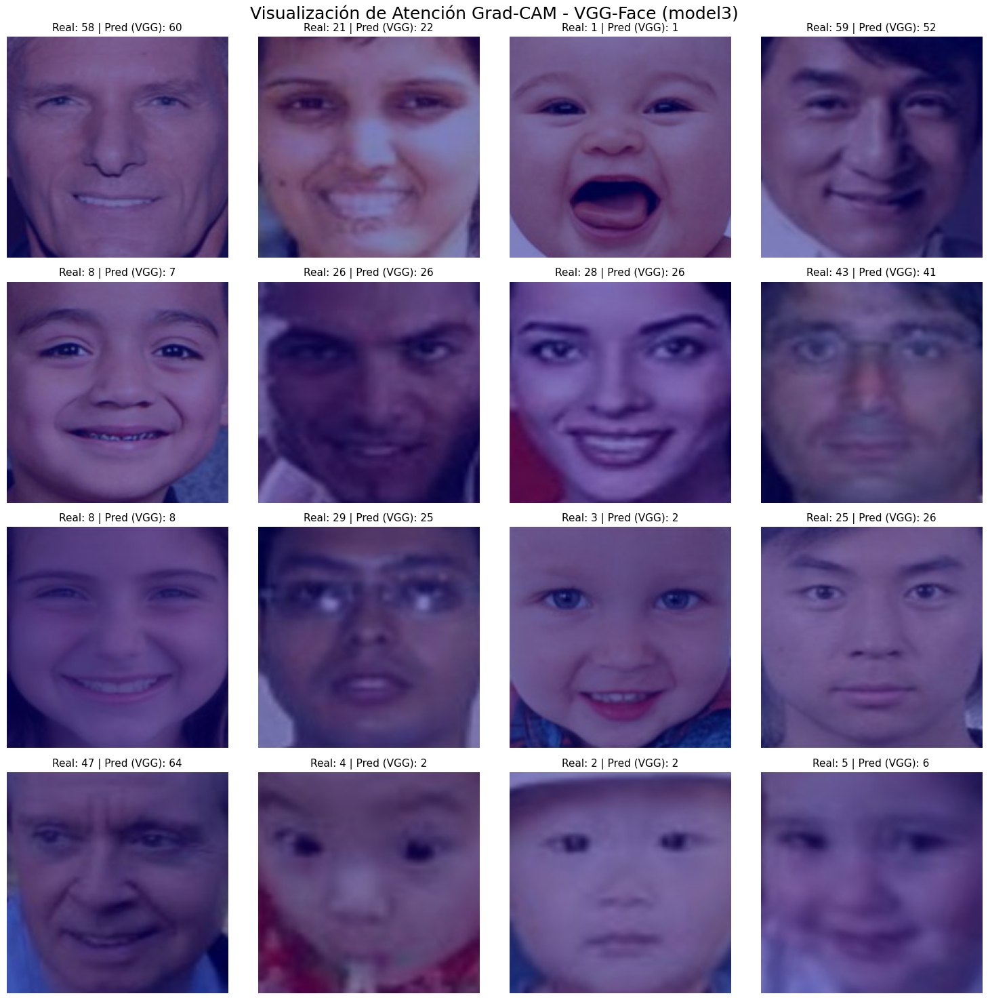

In [74]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Encontrar o forzar la capa objetivo para Grad-CAM.
# El usuario ha solicitado capturar la capa 'conv2d_39' por su mejor resolución de características.
target_layer_vgg = None
for layer in reversed(model3.model.layers):
    if layer.name == 'conv2d_39':
        target_layer_vgg = layer.name
        break

# Fallback en caso de que no se encuentre por nombre explícito
if target_layer_vgg is None:
    for layer in reversed(model3.model.layers):
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.MaxPooling2D)):
            if 'conv2d_40' not in layer.name:
                target_layer_vgg = layer.name
                break

print(f"Usando la capa objetivo para Grad-CAM en model3: {target_layer_vgg}")

def make_gradcam_heatmap_vgg(img_array, model, last_conv_layer_name):
    # Creamos un submodelo de activaciones y predicciones específico para el fine-tuning de VGG-Face
    grad_model = tf.keras.models.Model(
        inputs=[model.input],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        # Forzar el rastreo de las activaciones intermedias
        tape.watch(conv_outputs)
        loss = predictions[:, 0]

    # Obtenemos los gradientes de la predicción respecto a las activaciones de la capa seleccionada
    grads = tape.gradient(loss, conv_outputs)

    # Manejo de seguridad en caso de gradientes nulos (None) en capas específicas de VGG-Face
    if grads is None:
        grads = tf.zeros_like(conv_outputs)

    # Reducción de gradientes para ponderar canales
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar el mapa de características por la importancia de canal
    conv_outputs_val = conv_outputs[0]
    heatmap = conv_outputs_val @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalización del mapa de calor
    heatmap = tf.maximum(heatmap, 0.0)
    max_val = tf.reduce_max(heatmap)
    if max_val == 0.0:
        max_val = 1e-10
    heatmap = heatmap / max_val

    # Asegurar que sea devuelto como un array de NumPy estándar en 2D
    return np.array(heatmap.numpy(), dtype=np.float32)

def superimpose_heatmap_safe(img, heatmap, alpha=0.5, colormap=cv2.COLORMAP_JET):
    # Redimensionar el mapa de calor bidimensional al tamaño de la imagen original
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convertir a formato uint8 en el rango [0, 255]
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Aplicar el mapa de color
    heatmap_color = cv2.applyColorMap(heatmap_uint8, colormap)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    # Superponer sobre la imagen original
    superimposed_img = heatmap_color * alpha + img * (1.0 - alpha)
    return np.clip(superimposed_img, 0, 255).astype(np.uint8)

# Reiniciar el generador de pruebas para consistencia
fast_test_generator.reset()
x_test_batch_model3, y_test_batch_model3 = next(fast_test_generator)

# Graficar una cuadrícula de 4x4 con los mapas de calor Grad-CAM para model3
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch_model3[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar el mapa de calor usando la función robusta adaptada
    heatmap = make_gradcam_heatmap_vgg(img_input, model3.model, target_layer_vgg)

    # Convertir imagen normalizada (0-1) a rango 0-255 para superposición con OpenCV
    img_255 = np.uint8(img * 255)
    gradcam_img = superimpose_heatmap_safe(img_255, heatmap, alpha=0.5)

    real_age = int(y_test_batch_model3[i])
    predicted_age = int(round(float(model3.model.predict(img_input, verbose=0)[0][0])))

    # Dibujar subgráfico
    plt.subplot(4, 4, i + 1)
    plt.imshow(gradcam_img)
    plt.title(f"Real: {real_age} | Pred (VGG): {predicted_age}", fontsize=11)
    plt.axis('off')

plt.suptitle("Visualización de Atención Grad-CAM - VGG-Face (model3)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

### Guardar el Modelo Entrenado en Google Drive
Montamos Google Drive de forma segura y copiamos el archivo del modelo entrenado de VGG-Face (`vgg_face_finetuned.keras`) para respaldarlo.

In [76]:
from google.colab import drive
import shutil

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir rutas de origen y destino
origen = '/content/vgg_face_finetuned.keras'
destino = '/content/drive/MyDrive/vgg_face_finetuned.keras'

# 3. Copiar archivo con validación
try:
    shutil.copy(origen, destino)
    print("¡Modelo guardado exitosamente en tu Google Drive en la ruta:", destino)
except Exception as e:
    print("Ocurrió un error al copiar el archivo:", e)

Mounted at /content/drive
¡Modelo guardado exitosamente en tu Google Drive en la ruta: /content/drive/MyDrive/vgg_face_finetuned.keras
